# Dérive entre époques et comment faire mieux

**Constat de départ.** Les résultats ne dépassent pas la baseline : sur le clean test 2005–2009,
`Ridge + external` fait 3,413 contre 3,400 pour le naive, et rien n'est significatif. Sur la période
de développement 1995–2003, pourtant, le même modèle bat le naive de +0,277 position.

Ce notebook documente deux choses :

1. **la dérive** : les relations entre les features et la cible changent entre les deux époques ;
2. **les remèdes testés** : recency, fenêtres glissantes, cibles alternatives, sous-ensembles de
   features — et pourquoi aucun ne produit de gain significatif.

Il se termine par une **feuille de route** : ce qu'il faudrait réellement changer pour progresser.

**Protocole rappelé.** Sélection et tuning sur 1995–2003 uniquement (2004 absente). Clean test
2005–2009 touché seulement pour le rapport final. Unité = classement de conférence ; bootstrap
apparié sur `(year, confID)` ; significatif si l'IC 95 % est entièrement > 0.

## 1. Données et helpers

On reprend exactement le dataset et les 9 features sélectionnées du rapport `FEATURES_V2.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        ROOT = candidate
        break

import ranking_utils as ru
import ranking_features as rf

DEV = [y for y in range(1995, 2004) if y != 2004]
CLEAN = [2005, 2006, 2007, 2008, 2009]
ALL = [y for y in range(1995, 2010) if y != 2004]

df = ru.build_dataset(ru.load_teams())
ext, EXT_GROUPS = rf.build_external_features(ru.DATA_DIR)
df = df.merge(ext.drop(columns=["franchID"]), on=["year", "tmID"], how="left")
EXT_COLS = [c for g in EXT_GROUPS.values() for c in g]
df[EXT_COLS] = df[EXT_COLS].fillna(0.0)

SELECTION = json.loads((ROOT / "selected_features.json").read_text())
FEATS = SELECTION["features"]

print(f"Équipes-saisons : {len(df)} | features sélectionnées : {len(FEATS)}")
print(", ".join(FEATS))

Équipes-saisons : 732 | features sélectionnées : 9
pts_pct_z_lag1, sh_pct_lag1_z, sv_pct_lag1_z, pdo_lag1_z, shot_diff_lag1_z, shot_diff_pct_lag1_z, pdo_mean3_z, shot_diff_pct_mean3_z, n_hist


In [2]:
def make_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))


def walk_forward(features, target="target", years=DEV, weight_fn=None, window=None):
    outs = []
    for year in years:
        train = df[(df["year"] < year) & (df["n_hist"] >= 1)]
        if window is not None:
            train = train[train["year"] >= year - window]
        test = df[df["year"] == year]
        if test.empty or len(train) < 30:
            continue
        model = make_model()
        if weight_fn is None:
            model.fit(train[features], train[target])
        else:
            weights = weight_fn(year, train["year"].to_numpy())
            model.fit(train[features], train[target],
                      ridgecv__sample_weight=weights)
        out = test[["year", "tmID", "confID"]].copy()
        out["score"] = model.predict(test[features])
        outs.append(out)
    return pd.concat(outs, ignore_index=True)


def evaluate(pred):
    ranked = ru.rank_predictions(pred, df)
    return float(ru.season_metrics(ranked)["mae"].mean()), ranked


def compare(ref_ranked, cand_ranked):
    key = ["year", "tmID"]
    a = ref_ranked.set_index(key).sort_index()
    b = cand_ranked.set_index(key).sort_index()
    common = a.index.intersection(b.index)
    a, b = a.loc[common], b.loc[common]
    groups = (a["confID"] + "-"
              + a.index.get_level_values("year").astype(str)).to_numpy()
    gain, (low, high) = ru.paired_bootstrap(
        a["abs_err"].to_numpy(), b["abs_err"].to_numpy(), groups
    )
    return gain, low, high


naive_dev = ru.baseline_scores(df, "pts_pct_z_lag1", DEV)
naive_mae_dev, naive_r_dev = evaluate(naive_dev)
current_dev = walk_forward(FEATS, years=DEV)
current_mae_dev, current_r_dev = evaluate(current_dev)

naive_clean = ru.baseline_scores(df, "pts_pct_z_lag1", CLEAN)
naive_mae_clean, naive_r_clean = evaluate(naive_clean)
current_clean = walk_forward(FEATS, years=CLEAN)
current_mae_clean, current_r_clean = evaluate(current_clean)

print(f"DEV   : naive {naive_mae_dev:.3f} | Ridge {current_mae_dev:.3f}")
print(f"CLEAN : naive {naive_mae_clean:.3f} | Ridge {current_mae_clean:.3f}")

DEV   : naive 2.879 | Ridge 2.611
CLEAN : naive 3.400 | Ridge 3.413


## 2. La dérive, chiffrée

Deux diagnostics :

* la **corrélation de rang** entre chaque feature et la cible (`target`, le points percentage
  z-scoré), calculée séparément sur 1995–2003 et 2005–2009 ;
* les **coefficients Ridge** sur fenêtre expansive, pour voir si le modèle s'adapte à cette baisse.

In [3]:
rows = []
for feature in FEATS:
    for label, years in [("1995–2003", DEV), ("2005–2009", CLEAN)]:
        sub = df[df["year"].isin(years)]
        rho = sub[feature].corr(sub["target"], method="spearman")
        rows.append({"feature": feature, "époque": label, "spearman": rho})

drift = (pd.DataFrame(rows)
         .pivot(index="feature", columns="époque", values="spearman")
         .rename_axis(None, axis=1))
drift["delta"] = drift["2005–2009"] - drift["1995–2003"]
drift = drift.sort_values("delta")
display(drift.round(3))

,1995–2003,2005–2009,delta
feature,,,
shot_diff_pct_mean3_z,0.501,0.214,-0.288
n_hist,0.314,0.107,-0.208
shot_diff_pct_lag1_z,0.554,0.350,-0.204
shot_diff_lag1_z,0.552,0.348,-0.204
pts_pct_z_lag1,0.594,0.506,-0.088
sh_pct_lag1_z,0.232,0.166,-0.066
pdo_mean3_z,0.363,0.307,-0.056
pdo_lag1_z,0.292,0.310,0.019
sv_pct_lag1_z,0.209,0.302,0.093


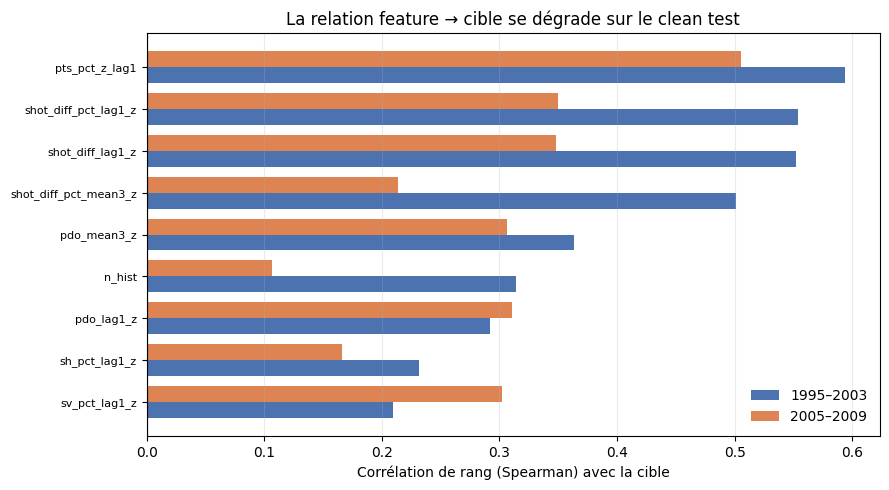

In [4]:
plot = drift.sort_values("1995–2003")
y = np.arange(len(plot))
height = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y - height / 2, plot["1995–2003"], height, label="1995–2003", color="#4C72B0")
ax.barh(y + height / 2, plot["2005–2009"], height, label="2005–2009", color="#DD8452")
ax.set_yticks(y)
ax.set_yticklabels(plot.index, fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Corrélation de rang (Spearman) avec la cible")
ax.set_title("La relation feature → cible se dégrade sur le clean test")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

Les features de **qualité de tir** perdent le plus :

* `shot_diff_pct_mean3_z` : 0,501 → 0,214 ;
* `shot_diff_lag1_z` : 0,552 → 0,348 ;
* `n_hist` : 0,314 → 0,107.

Le points percentage laggé reste la feature la plus stable (0,594 → 0,506). C'est cohérent avec le
fait que le naive soit si difficile à battre : la seule information robuste est déjà dans la
baseline.

Le coefficient de `sv_pct_lag1_z` augmente (0,209 → 0,302), mais cela ne suffit pas à compenser la
perte des autres blocs.

In [5]:
coef_rows = []
for year in ALL:
    train = df[(df["year"] < year) & (df["n_hist"] >= 1)]
    if len(train) < 50:
        continue
    model = make_model().fit(train[FEATS], train["target"])
    coef_rows.append(pd.Series(model[-1].coef_, index=FEATS, name=year))

coefs = pd.DataFrame(coef_rows)
display(coefs.loc[[y for y in coefs.index if y in (1995, 2000, 2003, 2005, 2009)]].round(2))

stability = pd.DataFrame({
    "1995–2003": coefs.loc[[y for y in coefs.index if y < 2004]].std(),
    "2005–2009": coefs.loc[[y for y in coefs.index if y >= 2005]].std(),
})
print("Écart-type des coefficients par époque :")
display(stability.round(3))

,pts_pct_z_lag1,sh_pct_lag1_z,sv_pct_lag1_z,pdo_lag1_z,shot_diff_lag1_z,shot_diff_pct_lag1_z,pdo_mean3_z,shot_diff_pct_mean3_z,n_hist
1995,0.26,0.30,0.15,-0.33,0.23,-0.03,0.21,0.07,0.03
2000,0.30,0.31,0.19,-0.41,0.22,0.03,0.22,0.01,0.02
2003,0.30,0.31,0.22,-0.45,0.23,0.02,0.22,0.03,0.02
2005,0.30,0.31,0.21,-0.44,0.24,0.03,0.22,0.02,0.02
2009,0.27,0.31,0.26,-0.39,0.23,0.06,0.16,-0.03,0.02


Écart-type des coefficients par époque :


,1995–2003,2005–2009
pts_pct_z_lag1,0.021,0.022
sh_pct_lag1_z,0.016,0.010
sv_pct_lag1_z,0.026,0.022
pdo_lag1_z,0.047,0.024
shot_diff_lag1_z,0.011,0.008
shot_diff_pct_lag1_z,0.024,0.013
pdo_mean3_z,0.012,0.023
shot_diff_pct_mean3_z,0.024,0.019
n_hist,0.006,0.002


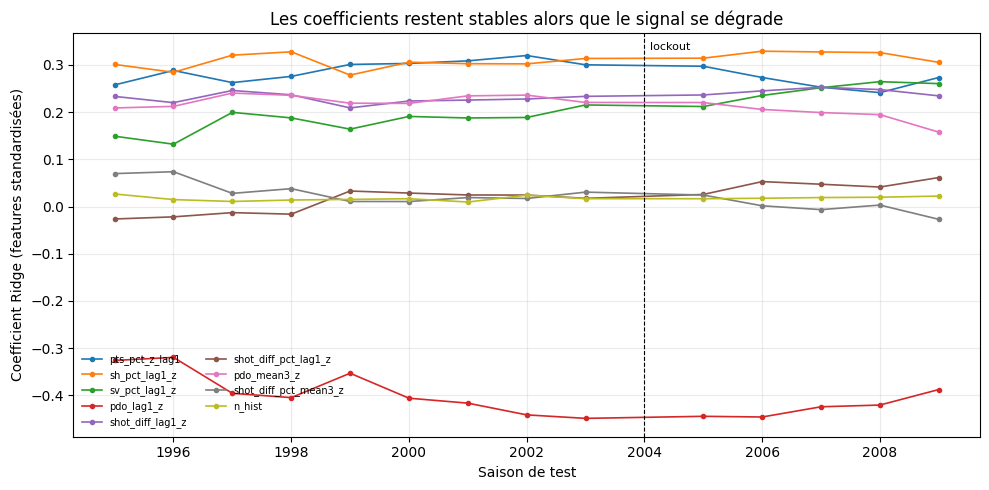

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for feature in FEATS:
    ax.plot(coefs.index, coefs[feature], marker="o", ms=3, lw=1.2, label=feature)
ax.axvline(2004, color="black", ls="--", lw=0.8)
ax.text(2004.1, ax.get_ylim()[1] * 0.9, "lockout", fontsize=8)
ax.set_xlabel("Saison de test")
ax.set_ylabel("Coefficient Ridge (features standardisées)")
ax.set_title("Les coefficients restent stables alors que le signal se dégrade")
ax.legend(frameon=False, fontsize=7, ncol=2)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Le modèle **ne s'adapte pas** : les coefficients varient peu entre les époques (écart-type ~0,01–0,03).
Il continue d'appliquer les mêmes poids à des features devenues moins prédictives. C'est une cause
directe de la contre-performance de 2006 et 2008, où le naive reprend l'avantage.

## 3. Les remèdes testés

Chaque candidat est évalué en walk-forward sur les deux périodes. La règle honnête est :

* on **choisit** un candidat sur 1995–2003 seulement ;
* on le **rapporte** ensuite sur 2005–2009, sans revenir en arrière.

Les colonnes `dev` et `clean` servent donc à montrer la stabilité, pas à sélectionner sur le clean.

In [7]:
recency_12 = lambda year, years: 0.5 ** ((year - years) / 12)
recency_20 = lambda year, years: 0.5 ** ((year - years) / 20)

CORE4 = ["pts_pct_z_lag1", "sh_pct_lag1_z", "sv_pct_lag1_z", "shot_diff_lag1_z"]
CORE5 = CORE4 + ["pdo_lag1_z"]

candidates = [
    ("Ridge + 9 features (référence)", dict(features=FEATS)),
    ("recency, demi-vie 12 ans", dict(features=FEATS, weight_fn=recency_12)),
    ("recency, demi-vie 20 ans", dict(features=FEATS, weight_fn=recency_20)),
    ("fenêtre glissante 12 ans", dict(features=FEATS, window=12)),
    ("fenêtre glissante 10 ans", dict(features=FEATS, window=10)),
    ("cible win_pct_z", dict(features=FEATS, target="win_pct_z")),
    ("cible gd_z", dict(features=FEATS, target="gd_z")),
    ("core 4 features", dict(features=CORE4)),
    ("core 5 + pdo", dict(features=CORE5)),
    ("sans n_hist", dict(features=[c for c in FEATS if c != "n_hist"])),
]

rows = []
for name, kwargs in candidates:
    pred_dev = walk_forward(**kwargs, years=DEV)
    pred_clean = walk_forward(**kwargs, years=CLEAN)
    mae_dev, r_dev = evaluate(pred_dev)
    mae_clean, r_clean = evaluate(pred_clean)
    gd, ld, hd = compare(current_r_dev, r_dev)
    gc, lc, hc = compare(current_r_clean, r_clean)
    rows.append({
        "candidat": name,
        "dev MAE": mae_dev, "dev gain": gd, "dev lo": ld, "dev hi": hd,
        "clean MAE": mae_clean, "clean gain": gc, "clean lo": lc, "clean hi": hc,
    })

cand = pd.DataFrame(rows).set_index("candidat")
cand["dev sig."] = cand["dev lo"] > 0
cand["clean sig."] = cand["clean lo"] > 0
display(cand.round(3))

,dev MAE,dev gain,dev lo,dev hi,clean MAE,clean gain,clean lo,clean hi,dev sig.,clean sig.
candidat,,,,,,,,,,
Ridge + 9 features (référence),2.611,0.000,0.000,0.000,3.413,0.000,0.000,0.000,False,False
"recency, demi-vie 12 ans",2.602,0.008,-0.048,0.064,3.360,0.053,-0.000,0.120,False,False
"recency, demi-vie 20 ans",2.617,-0.008,-0.055,0.039,3.347,0.067,-0.013,0.160,False,False
fenêtre glissante 12 ans,2.590,0.024,-0.056,0.108,3.440,-0.027,-0.173,0.120,False,False
fenêtre glissante 10 ans,2.605,0.008,-0.073,0.096,3.453,-0.040,-0.200,0.107,False,False
cible win_pct_z,2.594,0.016,-0.032,0.063,3.387,0.027,-0.053,0.107,False,False
cible gd_z,2.620,-0.008,-0.080,0.064,3.400,0.013,-0.080,0.120,False,False
core 4 features,2.818,-0.213,-0.363,-0.065,3.347,0.067,-0.200,0.347,False,False
core 5 + pdo,2.779,-0.174,-0.323,-0.024,3.320,0.093,-0.200,0.440,False,False


Lecture :

* **Aucun candidat n'est significatif sur le clean test** : tous les IC 95 % contiennent 0.
* La **recency 12 ans** est le compromis le plus net : elle améliore légèrement le dev (2,602 vs
  2,611) *et* le clean (3,360 vs 3,413), mais son gain vs le modèle courant est **+0,053
  [−0,000 ; +0,120]** : la borne basse touche zéro.
* La **cible `win_pct_z`** améliore aussi les deux périodes (dev 2,594, clean 3,387), mais le gain
  clean reste faible (**+0,027 [−0,053 ; +0,107]**). Ce n'est pas une amélioration prouvée.
* La **recency 20 ans** paraît meilleure sur le clean (3,347) mais elle est **pire sur le dev**
  (2,617). La retenir serait du cherry-picking sur le clean.
* Les **sous-ensembles** `core 4` et `core 5 + pdo` améliorent le clean (3,347 / 3,320) mais
  dégradent nettement le dev (2,818 / 2,779). Ils ne sont donc pas sélectionnables honnêtement : ils
  illustrent la dérive, ils ne la corrigent pas.
* Les **fenêtres glissantes** ne font pas mieux que le modèle courant, et `gd_z` reste dans le bruit.

## 4. Le détail par saison

L'agrégat peut cacher une année catastrophique. On regarde le gain du Ridge par rapport au naive,
saison par saison.

In [8]:
pred_all = walk_forward(FEATS, years=ALL)
naive_all = ru.baseline_scores(df, "pts_pct_z_lag1", ALL)
_, ridge_r_all = evaluate(pred_all)
_, naive_r_all = evaluate(naive_all)

ridge_year = ru.season_metrics(ridge_r_all).groupby("year")["mae"].mean()
naive_year = ru.season_metrics(naive_r_all).groupby("year")["mae"].mean()
by_year = pd.DataFrame({"naive": naive_year, "ridge": ridge_year})
by_year["gain ridge vs naive"] = by_year["naive"] - by_year["ridge"]
display(by_year.round(3))

,naive,ridge,gain ridge vs naive
year,,,
1995,2.231,1.923,0.308
1996,3.231,3.154,0.077
1997,2.923,2.923,0.000
1998,2.577,2.648,-0.071
1999,2.621,2.313,0.308
2000,2.533,2.067,0.467
2001,3.067,2.667,0.400
2002,3.533,2.867,0.667
2003,3.200,2.933,0.267


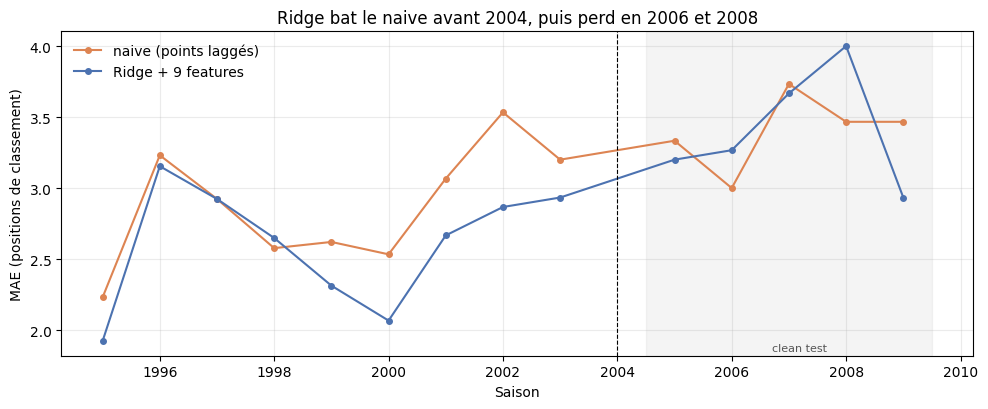

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(by_year.index, by_year["naive"], marker="o", ms=4, lw=1.5,
        color="#DD8452", label="naive (points laggés)")
ax.plot(by_year.index, by_year["ridge"], marker="o", ms=4, lw=1.5,
        color="#4C72B0", label="Ridge + 9 features")
ax.axvline(2004, color="black", ls="--", lw=0.8)
ax.axvspan(2004.5, 2009.5, color="#999999", alpha=0.10)
ax.text(2006.7, ax.get_ylim()[0] + 0.03, "clean test", fontsize=8, color="#555555")
ax.set_xlabel("Saison")
ax.set_ylabel("MAE (positions de classement)")
ax.set_title("Ridge bat le naive avant 2004, puis perd en 2006 et 2008")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Verdict et feuille de route

### Ce que dit l'analyse

1. **La dérive est réelle.** Les features de tirs/chance perdent une grande partie de leur pouvoir
   prédictif après 2004. Le modèle garde les mêmes coefficients et ne s'adapte pas.
2. **Aucun remède interne ne suffit.** Recency, fenêtres glissantes, cibles alternatives et
   sous-ensembles restent dans le bruit sur le clean test. Le meilleur candidat défendable
   (`recency 12 ans`) a un IC qui touche zéro.
3. **Le problème n'est pas le tuning.** Avec 10 classements de conférence dans le clean test, la
   puissance statistique est trop faible pour détecter un gain de 0,05 position. Continuer à tuner
   les mêmes features, c'est optimiser du bruit.

### Ce qu'il faudrait faire pour progresser

Par ordre de levier décroissant :

1. **Ajouter de l'information, pas des transformations.**
   - **Cotes / win totals de marché** avant la saison : c'est le prédicteur connu le plus fort.
     Même un blend simple avec le naive devrait aider si les lignes sont informatives.
   - **Projections joueur par joueur** : buts/points projetés, âge, temps de jeu, qualité du gardien.
     Les agrégats annuels actuels (nombre de joueurs à 20 buts, âge moyen) sont trop instables.
   - **Blessures, masse salariale, contrats, choix de repêchage** : information absente du dataset.
2. **Changer d'objectif.** La MAE du rang est grossière. Modéliser une **distribution de rangs** ou
   des **comparaisons par paires** (Plackett-Luce, Bradley-Terry), puis évaluer en log-loss / Brier,
   donne un signal plus riche et se prête mieux aux décisions (probabilité de playoffs, etc.).
3. **Augmenter la puissance du protocole.**
   - évaluer sur davantage de saisons (1950+ avec précautions) ou sur d'autres ligues ;
   - utiliser une validation rolling-origin pré-enregistrée sur toutes les saisons disponibles ;
   - accepter que le clean test 2005–2009 ne puisse pas trancher des gains < 0,1 position.
4. **Si on reste sur les données actuelles** :
   - conserver `Ridge + 9 features` comme modèle de référence et le blend `w≈0,95` avec le naive
     pour ne pas faire pire ;
   - documenter `recency 12 ans` comme candidat, avec la réserve explicite qu'il n'est pas
     significatif ;
   - ne pas sélectionner `core 4`, `core 5 + pdo` ni `recency 20 ans` sur la base du clean test.

### Ce qu'il ne faut pas faire

- Choisir un modèle parce qu'il est meilleur sur 2005–2009 : c'est exactement le cherry-picking que
  le protocole interdit.
- Noter un rang médian fractionnaire comme s'il s'agissait d'un classement (voir la correction dans
  `ranking_match_level.ipynb`).
- Présenter un gain dont l'IC contient zéro comme une amélioration.